In [35]:
#Settings
PRICE_TOLERANCE = {
    "EURUSD": 0.0001,   # 1 pip
    "GBPUSD": 0.0001,   # 1 pip
    "XAUUSD": 0.05,     # 5 cents per ounce
}

In [36]:
%pip install pandas numpy openpyxl matplotlib scipy yfinance pytest streamlit

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [37]:
%pip install matplotlib scipy yfinance pytest streamlit

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [38]:
import sys
print(sys.executable)
!"{sys.executable}" -m pip install matplotlib scipy yfinance pytest streamlit

C:\Users\Kwanz\Documents\Python Projects\Recon Tool\venv\Scripts\python.exe



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [39]:
import matplotlib
print("matplotlib", matplotlib.__version__)

matplotlib 3.11.2


In [40]:
import pandas, numpy, openpyxl, matplotlib, scipy, yfinance, pytest, streamlit
print("pandas", pandas.__version__, "| all imports OK")

pandas 3.0.6 | all imports OK


In [41]:
import pandas as pd

RAW = "Raw Data/"
internal_raw = pd.read_csv(RAW + "internal_blotter.csv")
broker_raw   = pd.read_csv(RAW + "broker_statement.csv")

print("Internal:", internal_raw.shape)
print("Broker:  ", broker_raw.shape)

Internal: (200, 8)
Broker:   (201, 8)


In [42]:
display(internal_raw.head(3))
display(broker_raw.head(3))

,trade_id,trade_date,symbol,side,quantity,price,counterparty,settle_date
0,T00033,2026-10-01,EURUSD,SELL,900000,1.15959,Absa,2026-10-05
1,T00050,2026-10-01,XAUUSD,BUY,1700,3975.80000,Absa,2026-10-05
2,T00072,2026-10-01,EURUSD,SELL,1300000,1.15493,FirstRand,2026-10-05


,TradeRef,Trade Date,Instrument,B/S,Qty,Exec Price,Cpty,Value Date
0,T00022,15/10/2026,gbpusd,S,1000000,1.31581,Standard Bank,19/10/2026
1,T00018,05/10/2026,eurusd,B,700000,1.15764,Absa,07/10/2026
2,T00059,06/10/2026,xauusd,S,200,3986.29000,FirstRand,08/10/2026


In [43]:
COLUMN_MAP = {
    "TradeRef":   "trade_id",
    "Trade Date": "trade_date",
    "Instrument": "symbol",
    "B/S":        "side",
    "Qty":        "quantity",
    "Exec Price": "price",
    "Cpty":       "counterparty",
    "Value Date": "settle_date",
}

broker   = broker_raw.rename(columns=COLUMN_MAP)
internal = internal_raw.copy()

print(list(internal.columns))
print(list(broker.columns))

['trade_id', 'trade_date', 'symbol', 'side', 'quantity', 'price', 'counterparty', 'settle_date']
['trade_id', 'trade_date', 'symbol', 'side', 'quantity', 'price', 'counterparty', 'settle_date']


In [44]:
for df in (internal, broker):
    df["trade_id"]     = df["trade_id"].str.strip().str.upper()
    df["symbol"]       = df["symbol"].str.strip().str.upper()
    df["counterparty"] = df["counterparty"].str.strip()
    df["side"]         = df["side"].str.strip().str.upper()

broker["side"] = broker["side"].replace({"B": "BUY", "S": "SELL"})

print("Symbols:", sorted(broker["symbol"].unique()))
print("Sides:  ", sorted(broker["side"].unique()))

Symbols: ['EURUSD', 'GBPUSD', 'XAUUSD']
Sides:   ['BUY', 'SELL']


In [45]:
internal["trade_date"]  = pd.to_datetime(internal["trade_date"],  format="%Y-%m-%d")
internal["settle_date"] = pd.to_datetime(internal["settle_date"], format="%Y-%m-%d")

broker["trade_date"]    = pd.to_datetime(broker["trade_date"],    format="%d/%m/%Y")
broker["settle_date"]   = pd.to_datetime(broker["settle_date"],   format="%d/%m/%Y")

print(internal[["trade_date", "settle_date"]].dtypes)
print(broker[["trade_date", "settle_date"]].dtypes)

trade_date     datetime64[us]
settle_date    datetime64[us]
dtype: object
trade_date     datetime64[us]
settle_date    datetime64[us]
dtype: object


In [46]:
for df in (internal, broker):
    df["quantity"] = pd.to_numeric(df["quantity"]).astype("int64")
    df["price"]    = pd.to_numeric(df["price"]).astype("float64")

print(internal[["quantity", "price"]].dtypes)
print(broker[["quantity", "price"]].dtypes)

quantity      int64
price       float64
dtype: object
quantity      int64
price       float64
dtype: object


In [47]:
COLUMNS = ["trade_id", "trade_date", "settle_date", "symbol",
           "side", "quantity", "price", "counterparty"]

internal = internal[COLUMNS]
broker   = broker[COLUMNS]

print(list(internal.columns) == list(broker.columns))

True


In [48]:
internal["is_duplicate"] = internal.duplicated(subset="trade_id", keep="first")
broker["is_duplicate"]   = broker.duplicated(subset="trade_id", keep="first")

print("Duplicates - internal:", internal["is_duplicate"].sum(),
      "| broker:", broker["is_duplicate"].sum())

dupe_ids = broker.loc[broker["is_duplicate"], "trade_id"]
display(broker[broker["trade_id"].isin(dupe_ids)].sort_values("trade_id"))

Duplicates - internal: 0 | broker: 2


,trade_id,trade_date,settle_date,symbol,side,quantity,price,counterparty,is_duplicate
168,T00002,2026-10-28,2026-10-30,XAUUSD,SELL,1600,4020.97,Nedbank,False
169,T00002,2026-10-28,2026-10-30,XAUUSD,SELL,1600,4020.97,Nedbank,True
45,T00075,2026-10-14,2026-10-16,XAUUSD,SELL,1300,4012.56,Nedbank,False
172,T00075,2026-10-14,2026-10-16,XAUUSD,SELL,1300,4012.56,Nedbank,True


In [49]:
assert list(internal.columns) == list(broker.columns), "Columns don't match"
assert (internal.dtypes == broker.dtypes).all(),       "Data types don't match"
assert internal.isna().sum().sum() == 0,               "Blanks in internal"
assert broker.isna().sum().sum() == 0,                 "Blanks in broker"
assert set(broker["side"]) <= {"BUY", "SELL"},         "Unknown side code"
assert set(broker["symbol"]) <= set(internal["symbol"]), "Unknown symbol"

print("All checks passed")
print(f"Internal: {len(internal)} rows | Broker: {len(broker)} rows")

All checks passed
Internal: 200 rows | Broker: 201 rows


In [50]:
import os

CLEAN = "Clean Data/"
os.makedirs(CLEAN, exist_ok=True)

internal.to_csv(CLEAN + "internal_clean.csv", index=False)
broker.to_csv(CLEAN + "broker_clean.csv", index=False)

print("Saved to:", os.listdir(CLEAN))

Saved to: ['broker_clean.csv', 'internal_clean.csv']


In [51]:
broker_dupes = broker[broker["is_duplicate"]]
broker_main  = broker[~broker["is_duplicate"]]

print("Duplicates set aside:", len(broker_dupes))
print("Broker rows to match:", len(broker_main))

Duplicates set aside: 2
Broker rows to match: 199


In [52]:
merged = internal.drop(columns="is_duplicate").merge(
    broker_main.drop(columns="is_duplicate"),
    on="trade_id",
    how="outer",
    suffixes=("_int", "_brk"),
    indicator=True,
)

print(merged["_merge"].value_counts())
print("Total rows:", len(merged))

_merge
both          196
left_only       4
right_only      3
Name: count, dtype: int64
Total rows: 203


In [53]:
display(merged.head())

,trade_id,trade_date_int,settle_date_int,symbol_int,side_int,quantity_int,price_int,counterparty_int,trade_date_brk,settle_date_brk,symbol_brk,side_brk,quantity_brk,price_brk,counterparty_brk,_merge
0,T00001,2026-10-13,2026-10-15,EURUSD,SELL,1300000.0,1.16264,Investec,2026-10-13,2026-10-15,EURUSD,SELL,1300000.0,1.16264,Investec,both
1,T00002,2026-10-28,2026-10-30,XAUUSD,SELL,1600.0,4020.97000,Nedbank,2026-10-28,2026-10-30,XAUUSD,SELL,1600.0,4020.97000,Nedbank,both
2,T00003,2026-10-15,2026-10-19,GBPUSD,BUY,1500000.0,1.31193,FirstRand,2026-10-15,2026-10-19,GBPUSD,BUY,1500000.0,1.31193,FirstRand,both
3,T00004,2026-10-22,2026-10-26,GBPUSD,SELL,300000.0,1.30011,Nedbank,2026-10-22,2026-10-26,GBPUSD,SELL,300000.0,1.30211,Nedbank,both
4,T00005,2026-10-15,2026-10-19,GBPUSD,BUY,1700000.0,1.29383,Investec,2026-10-15,2026-10-19,GBPUSD,BUY,1700000.0,1.29383,Investec,both


In [54]:
FALLBACK_KEYS = ["trade_date", "symbol", "side", "quantity"]

# 1. Pull out the unmatched trades from each side
unmatched_int = merged[merged["_merge"] == "left_only"]
unmatched_brk = merged[merged["_merge"] == "right_only"]

# 2. Keep the ID + the detail columns, and drop the _int / _brk endings
left = unmatched_int[["trade_id"] + [k + "_int" for k in FALLBACK_KEYS]]
left.columns = ["trade_id"] + FALLBACK_KEYS

right = unmatched_brk[["trade_id"] + [k + "_brk" for k in FALLBACK_KEYS]]
right.columns = ["trade_id"] + FALLBACK_KEYS

# 3. Try to pair them on the details
fallback = left.merge(right, on=FALLBACK_KEYS, suffixes=("_int", "_brk"))

print("Unmatched internal:", len(left), "| Unmatched broker:", len(right))
print("Fallback pairs found:", len(fallback))
display(fallback)

Unmatched internal: 4 | Unmatched broker: 3
Fallback pairs found: 0


,trade_id_int,trade_date,symbol,side,quantity,trade_id_brk


In [55]:
both = merged[merged["_merge"] == "both"].copy()

# Price: allowed to differ by up to the tolerance for that symbol
tolerance = both["symbol_int"].map(PRICE_TOLERANCE)
both["price_diff"] = (both["price_brk"] - both["price_int"]).abs()

# One True/False check per field
both["price_ok"]  = both["price_diff"] <= tolerance
both["qty_ok"]    = both["quantity_int"]    == both["quantity_brk"]
both["side_ok"]   = both["side_int"]        == both["side_brk"]
both["settle_ok"] = both["settle_date_int"] == both["settle_date_brk"]
both["tdate_ok"]  = both["trade_date_int"]  == both["trade_date_brk"]
both["symbol_ok"] = both["symbol_int"]      == both["symbol_brk"]

CHECKS = ["price_ok", "qty_ok", "side_ok", "settle_ok", "tdate_ok", "symbol_ok"]
both["all_ok"] = both[CHECKS].all(axis=1)

print("Failures per field:")
print((~both[CHECKS]).sum())
print("\nFully matched:", both["all_ok"].sum(), "of", len(both))

Failures per field:
price_ok     4
qty_ok       4
side_ok      3
settle_ok    3
tdate_ok     0
symbol_ok    0
dtype: int64

Fully matched: 182 of 196


In [56]:
display(both[both["trade_id"].isin(["T00126", "T00139", "T00198"])]
        [["trade_id", "symbol_int", "price_int", "price_brk", "price_diff", "price_ok"]])

,trade_id,symbol_int,price_int,price_brk,price_diff,price_ok
125,T00126,GBPUSD,1.30792,1.30793,0.00001,True
138,T00139,GBPUSD,1.31983,1.31984,0.00001,True
197,T00198,EURUSD,1.15357,1.15358,0.00001,True


In [57]:
BREAK_LABELS = {
    "price_ok":  "Price",
    "qty_ok":    "Quantity",
    "side_ok":   "Side",
    "settle_ok": "Settle Date",
    "tdate_ok":  "Trade Date",
    "symbol_ok": "Symbol",
}

def label_breaks(row):
    failed = [BREAK_LABELS[c] for c in CHECKS if not row[c]]
    return " + ".join(failed) if failed else "Matched"

both["break_type"] = both.apply(label_breaks, axis=1)

print(both["break_type"].value_counts())

break_type
Matched        182
Price            4
Quantity         4
Side             3
Settle Date      3
Name: count, dtype: int64


In [58]:
# Group 2: in your file only
missing_brk = merged[merged["_merge"] == "left_only"].copy()
missing_brk["break_type"] = "Missing in Broker"

# Group 3: in the broker's file only
missing_int = merged[merged["_merge"] == "right_only"].copy()
missing_int["break_type"] = "Missing Internal"

# Group 4: the duplicates set aside in Phase 4
dupes = (broker_dupes.drop(columns="is_duplicate")
         .add_suffix("_brk")
         .rename(columns={"trade_id_brk": "trade_id"}))
dupes["break_type"] = "Duplicate"

# Stack all 4 groups
recon = pd.concat([both, missing_brk, missing_int, dupes], ignore_index=True)

print(recon["break_type"].value_counts())
print("Total rows:", len(recon))

break_type
Matched              182
Price                  4
Quantity               4
Missing in Broker      4
Side                   3
Settle Date            3
Missing Internal       3
Duplicate              2
Name: count, dtype: int64
Total rows: 205


In [59]:
FIELDS = ["trade_date", "settle_date", "symbol", "side",
          "quantity", "price", "counterparty"]

# One clean column per field: use internal, and fall back to broker if blank
for col in FIELDS:
    recon[col] = recon[col + "_int"].fillna(recon[col + "_brk"])

# Money involved, in USD
recon["notional_usd"] = (recon["quantity"] * recon["price"]).round(2)

# Simple Matched / Break flag
recon["status"] = (recon["break_type"] == "Matched").map({True: "Matched", False: "Break"})

print(recon["status"].value_counts())
display(recon[recon["status"] == "Break"]
        [["trade_id", "symbol", "side", "quantity", "price", "break_type", "notional_usd"]]
        .sort_values("break_type"))

status
Matched    182
Break       23
Name: count, dtype: int64


,trade_id,symbol,side,quantity,price,break_type,notional_usd
203,T00002,XAUUSD,SELL,1600.0,4020.97000,Duplicate,6433552.0
204,T00075,XAUUSD,SELL,1300.0,4012.56000,Duplicate,5216328.0
200,T90001,XAUUSD,BUY,800.0,3980.75000,Missing Internal,3184600.0
201,T90002,XAUUSD,SELL,1800.0,4012.73000,Missing Internal,7222914.0
202,T90003,EURUSD,BUY,1800000.0,1.16017,Missing Internal,2088306.0
196,T00031,GBPUSD,BUY,1500000.0,1.31762,Missing in Broker,1976430.0
197,T00061,XAUUSD,SELL,400.0,4042.69000,Missing in Broker,1617076.0
198,T00142,EURUSD,BUY,1600000.0,1.16079,Missing in Broker,1857264.0
199,T00169,GBPUSD,SELL,300000.0,1.30939,Missing in Broker,392817.0
3,T00004,GBPUSD,SELL,300000.0,1.30011,Price,390033.0


In [60]:
key = pd.read_csv(RAW + "answer_key.csv")

# The within-tolerance trades should MATCH, so they're not breaks
key = key[~key["break_type"].str.startswith("Within")]

# What the tool found
found = recon.loc[recon["status"] == "Break", ["trade_id", "break_type"]]

# Line them up side by side
check = key.merge(found, on="trade_id", how="outer",
                  suffixes=("_expected", "_found"), indicator=True)
check["correct"] = check["break_type_expected"] == check["break_type_found"]

print("Planted breaks:", len(key))
print("Breaks found:  ", len(found))
print("Correct labels:", check["correct"].sum())

missed = check[~check["correct"]]
if missed.empty:
    print("\n✅ Every planted break caught and correctly labelled")
else:
    print("\n❌ Problems:")
    display(missed)

# Tolerance test: these 3 must be Matched
tol_ids = pd.read_csv(RAW + "answer_key.csv").query("break_type.str.startswith('Within')", engine="python")["trade_id"]
print("Tolerance trades matched:",
      (recon.loc[recon["trade_id"].isin(tol_ids), "status"] == "Matched").all())

Planted breaks: 23
Breaks found:   23
Correct labels: 23

✅ Every planted break caught and correctly labelled
Tolerance trades matched: True


In [61]:
MASTER_COLS = ["trade_id", "status", "break_type", "trade_date", "settle_date",
               "symbol", "side", "quantity", "price", "counterparty", "notional_usd"]

master = (recon[MASTER_COLS]
          .sort_values(["status", "break_type", "trade_id"])
          .reset_index(drop=True))
master["quantity"] = master["quantity"].astype("int64")

pd.set_option("display.max_rows", None)
display(master)

,trade_id,status,break_type,trade_date,settle_date,symbol,side,quantity,price,counterparty,notional_usd
0,T00002,Break,Duplicate,2026-10-28,2026-10-30,XAUUSD,SELL,1600,4020.97000,Nedbank,6433552.0
1,T00075,Break,Duplicate,2026-10-14,2026-10-16,XAUUSD,SELL,1300,4012.56000,Nedbank,5216328.0
2,T90001,Break,Missing Internal,2026-10-15,2026-10-19,XAUUSD,BUY,800,3980.75000,Investec,3184600.0
3,T90002,Break,Missing Internal,2026-10-07,2026-10-09,XAUUSD,SELL,1800,4012.73000,Absa,7222914.0
4,T90003,Break,Missing Internal,2026-10-12,2026-10-14,EURUSD,BUY,1800000,1.16017,FirstRand,2088306.0
5,T00031,Break,Missing in Broker,2026-10-15,2026-10-19,GBPUSD,BUY,1500000,1.31762,Absa,1976430.0
6,T00061,Break,Missing in Broker,2026-10-26,2026-10-28,XAUUSD,SELL,400,4042.69000,Standard Bank,1617076.0
7,T00142,Break,Missing in Broker,2026-10-09,2026-10-13,EURUSD,BUY,1600000,1.16079,Absa,1857264.0
8,T00169,Break,Missing in Broker,2026-10-01,2026-10-05,GBPUSD,SELL,300000,1.30939,Nedbank,392817.0
9,T00004,Break,Price,2026-10-22,2026-10-26,GBPUSD,SELL,300000,1.30011,Nedbank,390033.0


In [62]:
summary = (master.groupby("break_type")
           .agg(trades=("trade_id", "count"),
                notional_usd=("notional_usd", "sum"))
           .sort_values("notional_usd", ascending=False)
           .reset_index())

total = pd.DataFrame([{"break_type":   "TOTAL",
                       "trades":       summary["trades"].sum(),
                       "notional_usd": summary["notional_usd"].sum()}])
summary = pd.concat([summary, total], ignore_index=True)

display(summary)

breaks_only = summary[~summary["break_type"].isin(["Matched", "TOTAL"])]
match_rate  = (master["status"] == "Matched").mean()

print(f"Match rate: {match_rate:.1%}")
print(f"Breaks:     {breaks_only['trades'].sum()}")
print(f"At risk:    ${breaks_only['notional_usd'].sum():,.0f}")

,break_type,trades,notional_usd
0,Matched,182,453445069.0
1,Missing Internal,3,12495820.0
2,Duplicate,2,11649880.0
3,Quantity,4,7788487.0
4,Missing in Broker,4,5843587.0
5,Settle Date,3,5829153.0
6,Price,4,4853956.0
7,Side,3,4503885.0
8,TOTAL,205,506409837.0


Match rate: 88.8%
Breaks:     23
At risk:    $52,964,768


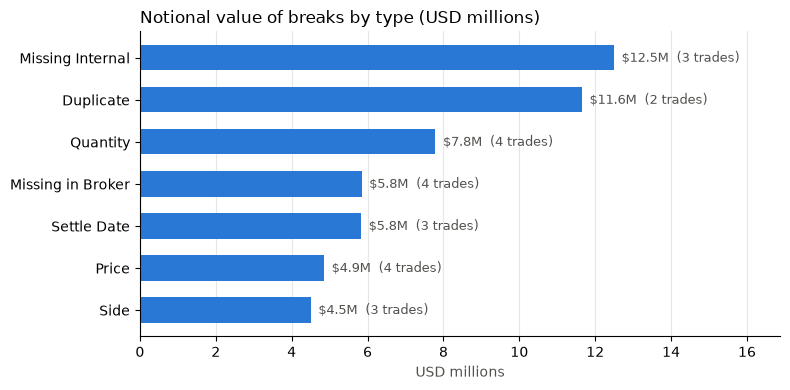

In [63]:
import os
import matplotlib.pyplot as plt

OUTPUT = "Output/"
os.makedirs(OUTPUT, exist_ok=True)

chart = breaks_only.sort_values("notional_usd")

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(chart["break_type"], chart["notional_usd"] / 1e6,
               color="#2a78d6", height=0.6)

# Value labels at the end of each bar
for bar, n in zip(bars, chart["trades"]):
    ax.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height() / 2,
            f"${bar.get_width():.1f}M  ({n} trades)",
            va="center", fontsize=9, color="#52514e")

# Styling
ax.set_title("Notional value of breaks by type (USD millions)", loc="left", fontsize=12)
ax.set_xlabel("USD millions", color="#52514e")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#e6e6e2", linewidth=0.8)
ax.set_axisbelow(True)
ax.set_xlim(0, chart["notional_usd"].max() / 1e6 * 1.35)

plt.tight_layout()
plt.savefig(OUTPUT + "breaks_by_type.png", dpi=150)
plt.show()

In [64]:
from datetime import date

report_file = OUTPUT + f"recon_report_{date.today():%Y-%m-%d}.xlsx"

breaks  = master[master["status"] == "Break"]
matched = master[master["status"] == "Matched"]

with pd.ExcelWriter(report_file, engine="openpyxl") as writer:
    summary.to_excel(writer, sheet_name="Summary", index=False)
    breaks.to_excel(writer,  sheet_name="Breaks",  index=False)
    matched.to_excel(writer, sheet_name="Matched", index=False)

    # Tidy every tab: fit column widths and freeze the header row
    for sheet in writer.sheets.values():
        for col in sheet.columns:
            width = max(len(str(c.value)) if c.value is not None else 0 for c in col)
            sheet.column_dimensions[col[0].column_letter].width = width + 3
        sheet.freeze_panes = "A2"

print("Saved:", report_file)

Saved: Output/recon_report_2026-11-10.xlsx
